# Part 1: Data Preparation and Exploration
**MGSC 661, Group 12: Predicting next-hour net bike loss at Capital Bikeshare stations**

This notebook builds the shared dataset that the rest of the team uses for modelling:

1. Load one month per season of Capital Bikeshare trip files: **January, May, August and October 2026**
2. Check missing values and data quality, then clean
3. Aggregate trips into **station-hour** rows (departures, arrivals, net flow)
4. Build the target: **next-hour net bike loss** = departures minus arrivals in the following hour
5. Add features: lagged net flow, calendar, weather, station capacity
6. Create **chronological** train / validation / test splits **inside each month**, so every season appears in all three
7. Exploratory charts: demand by hour, by weekday, and by weather

**Output:** `output/station_hour_{train,val,test}.csv.gz`, shared with Parts 2 to 4.

## 0. Setup

In [1]:
import glob, io, os, zipfile, urllib.request, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False})

### Configuration
Put the monthly CSVs (or zips) in `DATA_DIR`. Set `DOWNLOAD = True` to fetch the 4 zips (about 90 MB) from the Capital Bikeshare S3 bucket automatically.

**Why split inside each month?** The 4 months are not consecutive. A plain time split would make October the entire test set, so the model would train on 3 seasons and be tested on a different one. Instead, every month is split the same way by day:

| Days of each month | Use |
|---|---|
| 1 to 7 | Only used to build the one-week lag (dropped) |
| 8 to 21 | Train |
| 22 to 25 | Validation |
| 26 to end | Test |

In [2]:
DATA_DIR = "."             # CSVs sit in the same folder as the notebook
OUT_DIR = "output"

MONTHS = ["202601", "202605", "202608", "202610"]   # winter, spring, summer, fall

N_STATIONS = 100

TRAIN_LAST_DAY = 21
VAL_LAST_DAY = 25

SEASON = {1: "winter", 5: "spring", 8: "summer", 10: "fall"}

def split_of(ts):
    d = ts.dt.day
    return np.select([d <= TRAIN_LAST_DAY, d <= VAL_LAST_DAY], ["train", "val"], "test")

DC_LAT, DC_LON = 38.9072, -77.0369
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the trip data

In [3]:
files = [os.path.join(DATA_DIR, f"{m}-capitalbikeshare-tripdata.csv") for m in MONTHS]
trips = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
trips["started_at"] = pd.to_datetime(trips["started_at"], format="mixed")
trips["ended_at"] = pd.to_datetime(trips["ended_at"], format="mixed")
print(f"{len(files)} files, {len(trips):,} trips")
trips.head()

4 files, 2,176,592 trips


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,03FA2293C051163C,classic_bike,2026-01-04 15:56:26.146,2026-01-04 16:02:56.393,8th & K St NE,31660.0,New York Ave & Hecht Ave NE,31518.0,38.902594,-76.995141,38.915604,-76.983683,member
1,01C478AD5DD27444,electric_bike,2026-01-17 15:12:11.912,2026-01-17 15:17:58.238,8th & K St NE,31660.0,New York Ave & Hecht Ave NE,31518.0,38.902594,-76.995141,38.915604,-76.983683,member
2,064CCCADB41E193C,electric_bike,2026-01-13 21:17:51.779,2026-01-13 21:21:45.187,Georgia Ave & Dahlia St NW,31425.0,Takoma Metro,31408.0,38.976061,-77.026747,38.975219,-77.016855,member
3,4C990F7ED7C1D93A,electric_bike,2026-01-07 21:11:24.346,2026-01-07 21:15:32.600,Georgia Ave & Dahlia St NW,31425.0,Takoma Metro,31408.0,38.976061,-77.026747,38.975219,-77.016855,member
4,DACE615CE7D9E441,electric_bike,2026-01-16 08:54:26.216,2026-01-16 09:01:43.052,2nd St & Seaton Pl NE,31522.0,John McCormack Rd & Michigan Ave NE,31502.0,38.914751,-77.003560,38.934600,-76.995500,member


## 2. Missing values and data quality

In [4]:
missing = trips.isna().mean().mul(100).round(1).rename("% missing")
missing.to_frame()

,% missing
ride_id,0.0
rideable_type,0.0
started_at,0.0
ended_at,0.0
start_station_name,14.5
start_station_id,14.5
end_station_name,15.4
end_station_id,15.4
start_lat,0.0
start_lng,0.0


In [5]:
# Are the trips without a station all e-bikes (parked outside a dock)?
no_station = trips["start_station_id"].isna() | trips["end_station_id"].isna()
print(f"trips missing a start or end station: {no_station.mean():.1%}")
print(trips.loc[no_station, "rideable_type"].value_counts(normalize=True).round(3))

trips missing a start or end station: 24.3%
rideable_type
electric_bike    0.998
classic_bike     0.002
Name: proportion, dtype: float64


In [6]:
trips["duration_min"] = (trips["ended_at"] - trips["started_at"]).dt.total_seconds() / 60
print(trips["duration_min"].describe().round(1))
print("zero or negative duration:", (trips["duration_min"] <= 0).sum())
print("longer than 24 hours:     ", (trips["duration_min"] > 24 * 60).sum())

count    2176592.0
mean          13.3
std           42.2
min            0.0
25%            5.2
50%            8.6
75%           14.3
max         1500.4
Name: duration_min, dtype: float64
zero or negative duration: 0
longer than 24 hours:      1276


### Cleaning rules
- **Drop trips with no start or end station.** These are dockless e-bike trips and do not move bikes between docks in the same way.
- **Drop trips with duration ≤ 0 or > 24 hours** (clock errors or bikes that were never returned properly).
- **Keep only trips that start inside one of the 4 study months.** Each monthly file contains a few trips from the previous month.

In [7]:
n0 = len(trips)
loaded = [os.path.basename(f)[:6] for f in files]   # only months whose file was found
periods = [pd.Period(m, "M") for m in loaded]
start, end = periods[0].start_time, periods[-1].end_time

clean = trips[
    ~no_station
    & trips["duration_min"].between(0, 24 * 60, inclusive="right")
    & trips["started_at"].dt.to_period("M").isin(periods)
].copy()

clean["start_station_id"] = clean["start_station_id"].astype("int64")
clean["end_station_id"] = clean["end_station_id"].astype("int64")
print(f"kept {len(clean):,} of {n0:,} trips ({len(clean)/n0:.1%}); removed {n0-len(clean):,}")

kept 1,646,866 of 2,176,592 trips (75.7%); removed 529,726


## 3. Aggregate to station-hour
Departures are counted at the start station in the hour the trip starts; arrivals at the end station in the hour it ends.

In [8]:
clean["start_hour"] = clean["started_at"].dt.floor("h")
clean["end_hour"] = clean["ended_at"].dt.floor("h")
clean["is_casual"] = (clean["member_casual"] == "casual").astype(int)
clean["is_ebike"] = (clean["rideable_type"] == "electric_bike").astype(int)

dep = (clean.groupby(["start_station_id", "start_hour"])
       .agg(departures=("ride_id", "size"),
            casual_dep=("is_casual", "sum"),
            ebike_dep=("is_ebike", "sum"))
       .rename_axis(["station_id", "hour"]))
arr = (clean.groupby(["end_station_id", "end_hour"]).size()
       .rename("arrivals").rename_axis(["station_id", "hour"]))

### Choose the busiest stations
To keep the dataset manageable, we model the `N_STATIONS` busiest stations. They are chosen using **training days only**, so the test days do not influence which stations we study.

In [9]:
train_mask = lambda idx: split_of(idx.get_level_values("hour").to_series()) == "train"
activity = (dep.loc[train_mask(dep.index), "departures"].groupby("station_id").sum()
            .add(arr.loc[train_mask(arr.index)].groupby("station_id").sum(), fill_value=0)
            .sort_values(ascending=False))
top_ids = activity.head(N_STATIONS).index
print(f"top {N_STATIONS} of {len(activity)} stations carry {activity.head(N_STATIONS).sum()/activity.sum():.1%} of training-period activity")

top 100 of 876 stations carry 46.1% of training-period activity


Build a **complete** grid (every station × every hour of the 4 months, zeros included). Without the zero rows, lag features would skip hours and be wrong.

In [10]:
hours = pd.DatetimeIndex(np.concatenate([
    pd.date_range(p.start_time, p.end_time.floor("h"), freq="h") for p in periods]))
grid = pd.MultiIndex.from_product([top_ids, hours], names=["station_id", "hour"])

sh = (pd.DataFrame(index=grid)
      .join(dep).join(arr)
      .fillna(0).astype(int)
      .reset_index()
      .sort_values(["station_id", "hour"]))
sh["net_loss"] = sh["departures"] - sh["arrivals"]          # >0 means the station lost bikes this hour
sh["casual_share"] = (sh["casual_dep"] / sh["departures"]).fillna(0)
sh["ebike_share"] = (sh["ebike_dep"] / sh["departures"]).fillna(0)
sh = sh.drop(columns=["casual_dep", "ebike_dep"])
sh["month_key"] = sh["hour"].dt.to_period("M").astype(str)
sh["season"] = sh["hour"].dt.month.map(SEASON)
print(f"{len(sh):,} station-hour rows ({len(top_ids)} stations x {len(hours):,} hours)")
print(f"share of station-hours with no trips: {((sh.departures == 0) & (sh.arrivals == 0)).mean():.1%}")

297,600 station-hour rows (100 stations x 2,976 hours)
share of station-hours with no trips: 25.6%


## 4. Target and lag features
All shifts are done **within each station and month**, so a lag never reaches across the gap between two months.

In [11]:
g = sh.groupby(["station_id", "month_key"])["net_loss"]

# TARGET: net bike loss in the NEXT hour
sh["target_next_net_loss"] = g.shift(-1)

# Lags: what happened recently at this station (all known at prediction time)
sh["net_lag0"] = sh["net_loss"]            # current hour
sh["net_lag1"] = g.shift(1)
sh["net_lag2"] = g.shift(2)
sh["net_lag3"] = g.shift(3)
sh["net_sum_3h"] = sh["net_lag0"] + sh["net_lag1"] + sh["net_lag2"]
sh["net_lag_1w"] = g.shift(168 - 1)        # same hour as the TARGET hour, one week earlier
sh["dep_lag_1w"] = sh.groupby(["station_id", "month_key"])["departures"].shift(168 - 1)

### Historical-average baseline (for Part 2)
Average net loss for each station × weekday × hour, computed on **training data only** and attached to every row. This is the baseline the models must beat.

In [12]:
sh["target_hour"] = sh["hour"] + pd.Timedelta(hours=1)
sh["t_dow"] = sh["target_hour"].dt.dayofweek
sh["t_hod"] = sh["target_hour"].dt.hour

hist = (sh[(split_of(sh["target_hour"]) == "train") & sh["net_lag_1w"].notna()]
        .groupby(["station_id", "t_dow", "t_hod"])["target_next_net_loss"].mean()
        .rename("baseline_hist_avg"))
sh = sh.join(hist, on=["station_id", "t_dow", "t_hod"])

## 5. Calendar, station and weather features

In [13]:
holidays = USFederalHolidayCalendar().holidays(start, end)
sh["hour_of_day"] = sh["t_hod"]                  # calendar features describe the TARGET hour
sh["day_of_week"] = sh["t_dow"]
sh["is_weekend"] = (sh["t_dow"] >= 5).astype(int)
sh["is_holiday"] = sh["target_hour"].dt.normalize().isin(holidays).astype(int)
sh["month"] = sh["target_hour"].dt.month
sh = sh.drop(columns=["t_dow", "t_hod"])

**Station information** from the live GBFS feed: coordinates and capacity (number of docks). Trip files use the short station number, which matches the feed's `short_name`.

In [14]:
try:
    url = "https://gbfs.lyft.com/gbfs/2.3/dca-cabi/en/station_information.json"
    info = pd.DataFrame(json.load(urllib.request.urlopen(url, timeout=30))["data"]["stations"])
    info = info[["short_name", "name", "lat", "lon", "capacity"]].copy()
    info["station_id"] = pd.to_numeric(info["short_name"], errors="coerce")
    info = info.dropna(subset=["station_id"]).astype({"station_id": "int64"}).drop_duplicates("station_id")
    sh = sh.merge(info[["station_id", "lat", "lon", "capacity"]], on="station_id", how="left")
    print("stations matched to GBFS:", sh.drop_duplicates("station_id")["capacity"].notna().sum(), "of", len(top_ids))
except Exception as e:
    print("GBFS not available, using coordinates from the trip data instead:", e)
    coords = clean.groupby("start_station_id")[["start_lat", "start_lng"]].median()
    coords.columns = ["lat", "lon"]
    sh = sh.merge(coords, left_on="station_id", right_index=True, how="left")
    sh["capacity"] = np.nan

names = clean.groupby("start_station_id")["start_station_name"].agg(lambda s: s.mode().iat[0])
sh["station_name"] = sh["station_id"].map(names)

stations matched to GBFS: 100 of 100


**Hourly weather** for Washington, DC from the free [Open-Meteo historical API](https://open-meteo.com/en/docs/historical-weather-api) (no key needed), in local time.

In [15]:
try:
    wurl = ("https://archive-api.open-meteo.com/v1/archive"
            f"?latitude={DC_LAT}&longitude={DC_LON}"
            f"&start_date={start:%Y-%m-%d}&end_date={end:%Y-%m-%d}"
            "&hourly=temperature_2m,precipitation,wind_speed_10m"
            "&timezone=America%2FNew_York")
    w = pd.DataFrame(json.load(urllib.request.urlopen(wurl, timeout=60))["hourly"])
    w["time"] = pd.to_datetime(w["time"])
    w = (w.drop_duplicates("time")
          .rename(columns={"time": "target_hour", "temperature_2m": "temp_c",
                           "precipitation": "precip_mm", "wind_speed_10m": "wind_kmh"}))
    sh = sh.merge(w, on="target_hour", how="left")
    sh["is_raining"] = (sh["precip_mm"] > 0.1).astype(int)
    print("weather rows:", len(w), "| missing weather after join:", sh["temp_c"].isna().mean().round(4))
except Exception as e:
    print("weather not available:", e)
    HAVE_WEATHER = False
else:
    HAVE_WEATHER = True

weather rows: 7296 | missing weather after join: 0.0003


## 6. Chronological train / validation / test split

In [16]:
# Drop rows whose lags or target are undefined (first week of data, last hour)
model_df = sh.dropna(subset=["target_next_net_loss", "net_lag3", "net_lag_1w"]).copy()
model_df["target_next_net_loss"] = model_df["target_next_net_loss"].astype(int)

t = model_df["target_hour"]
model_df["split"] = split_of(t)

summary = (model_df.groupby(["season", "split"])
           .agg(rows=("station_id", "size"), first=("target_hour", "min"), last=("target_hour", "max")))
summary

rows      first                last
season split                                      
fall   test   14400 2026-10-26 2026-10-31 23:00:00
       train  33600 2026-10-08 2026-10-21 23:00:00
       val     9600 2026-10-22 2026-10-25 23:00:00
spring test   14400 2026-05-26 2026-05-31 23:00:00
       train  33600 2026-05-08 2026-05-21 23:00:00
       val     9600 2026-05-22 2026-05-25 23:00:00
summer test   14400 2026-08-26 2026-08-31 23:00:00
       train  33600 2026-08-08 2026-08-21 23:00:00
       val     9600 2026-08-22 2026-08-25 23:00:00
winter test   14400 2026-01-26 2026-01-31 23:00:00
       train  33600 2026-01-08 2026-01-21 23:00:00
       val     9600 2026-01-22 2026-01-25 23:00:00

In [17]:
cols = ["station_id", "station_name", "season", "hour", "target_hour",
        "target_next_net_loss", "baseline_hist_avg",
        "departures", "arrivals", "net_lag0", "net_lag1", "net_lag2", "net_lag3", "net_sum_3h",
        "net_lag_1w", "dep_lag_1w", "casual_share", "ebike_share",
        "hour_of_day", "day_of_week", "is_weekend", "is_holiday", "month",
        "lat", "lon", "capacity",
        "temp_c", "precip_mm", "wind_kmh", "is_raining"]
cols = [c for c in cols if c in model_df.columns]

for name in ["train", "val", "test"]:
    part = model_df.loc[model_df["split"] == name, cols]
    path = os.path.join(OUT_DIR, f"station_hour_{name}.csv.gz")
    part.to_csv(path, index=False)
    print(f"saved {path}: {len(part):,} rows")

saved output/station_hour_train.csv.gz: 134,400 rows
saved output/station_hour_val.csv.gz: 38,400 rows
saved output/station_hour_test.csv.gz: 57,600 rows


### Data dictionary
| Column | Meaning |
|---|---|
| `target_next_net_loss` | **Target.** Departures minus arrivals in the next hour (positive = station losing bikes) |
| `baseline_hist_avg` | Training-set average of the target for this station, weekday and hour (baseline) |
| `net_lag0` to `net_lag3` | Net loss in the current hour and the 1 to 3 hours before |
| `net_sum_3h` | Total net loss over the last 3 hours |
| `net_lag_1w`, `dep_lag_1w` | Net loss and departures at the target hour one week earlier |
| `casual_share`, `ebike_share` | Share of this hour's departures by casual riders / on e-bikes |
| `season` | winter (Jan), spring (May), summer (Aug), fall (Oct) |
| `hour_of_day`, `day_of_week`, `is_weekend`, `is_holiday`, `month` | Calendar features of the target hour |
| `lat`, `lon`, `capacity` | Station location and number of docks |
| `temp_c`, `precip_mm`, `wind_kmh`, `is_raining` | Weather at the target hour |

## 7. Exploratory charts

### Chart 1: Demand by hour of day

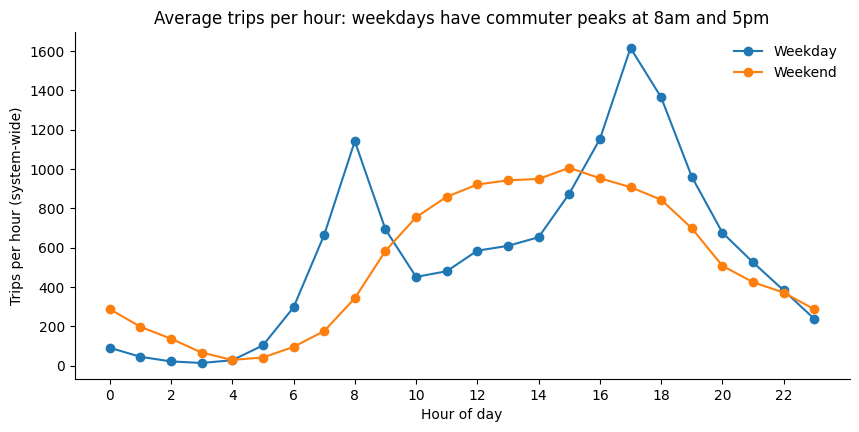

In [18]:
c = clean.assign(hod=clean["started_at"].dt.hour, weekend=clean["started_at"].dt.dayofweek >= 5)
n_days = c.groupby("weekend")["started_at"].apply(lambda s: s.dt.date.nunique())
by_hour = c.groupby(["weekend", "hod"]).size().div(n_days, level="weekend").unstack(0)

fig, ax = plt.subplots()
ax.plot(by_hour.index, by_hour[False], marker="o", label="Weekday")
ax.plot(by_hour.index, by_hour[True], marker="o", label="Weekend")
ax.set(title="Average trips per hour: weekdays have commuter peaks at 8am and 5pm",
       xlabel="Hour of day", ylabel="Trips per hour (system-wide)", xticks=range(0, 24, 2))
ax.legend(frameon=False)
plt.show()

### Chart 1b: Net bike loss by hour, residential vs. downtown station
The system-wide total hides the real problem. Residential stations **lose** bikes in the morning while downtown stations **gain** them, then the pattern reverses in the evening. We pick the two stations with the strongest opposite morning patterns.

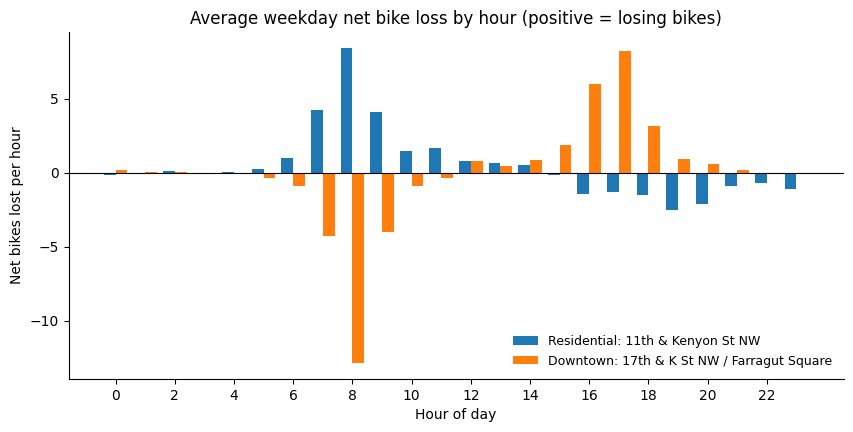

In [19]:
wk = sh[sh["hour"].dt.dayofweek < 5]
profile = wk.groupby(["station_id", wk["hour"].dt.hour])["net_loss"].mean().unstack()
morning = profile[[7, 8, 9]].mean(axis=1)
res_id, dt_id = morning.idxmax(), morning.idxmin()

fig, ax = plt.subplots()
ax.bar(profile.columns - 0.2, profile.loc[res_id], width=0.4, label=f"Residential: {names[res_id]}")
ax.bar(profile.columns + 0.2, profile.loc[dt_id], width=0.4, label=f"Downtown: {names[dt_id]}")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Average weekday net bike loss by hour (positive = losing bikes)",
       xlabel="Hour of day", ylabel="Net bikes lost per hour", xticks=range(0, 24, 2))
ax.legend(frameon=False, fontsize=9)
plt.show()

### Chart 2: Demand by day of week

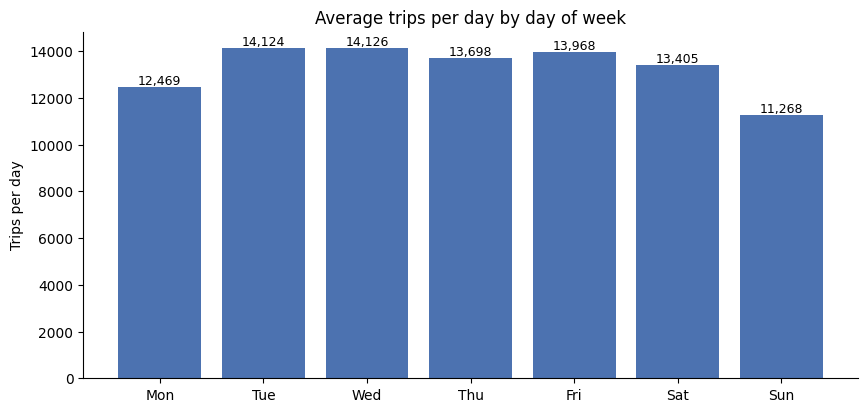

In [20]:
c["date"] = c["started_at"].dt.date
daily = c.groupby("date").size().rename("trips").reset_index()
daily["dow"] = pd.to_datetime(daily["date"]).dt.dayofweek
by_dow = daily.groupby("dow")["trips"].mean()

fig, ax = plt.subplots()
ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_dow.values, color="#4C72B0")
ax.set(title="Average trips per day by day of week", ylabel="Trips per day")
for i, v in enumerate(by_dow.values):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.show()

### Chart 3: Demand by weather

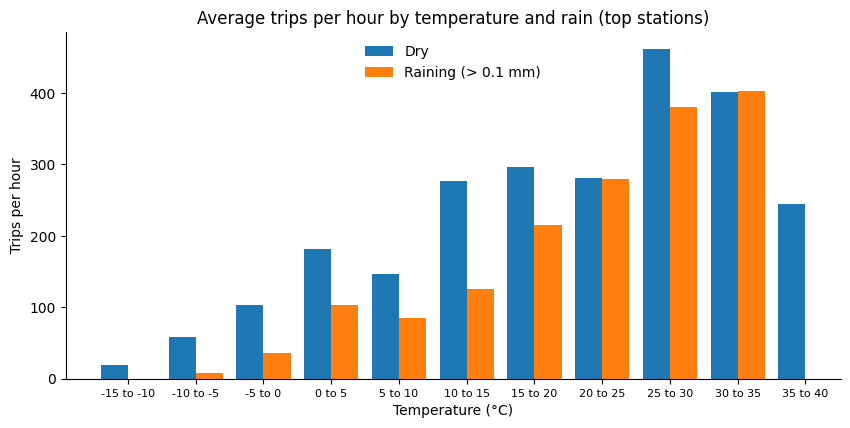

In [21]:
if HAVE_WEATHER:
    hourly = (sh.groupby("target_hour")
                .agg(trips=("departures", "sum"), temp_c=("temp_c", "first"), is_raining=("is_raining", "first"))
                .dropna())
    hourly["trips"] = hourly["trips"]  # departures from the modelled stations
    hourly["temp_bin"] = pd.cut(hourly["temp_c"], bins=range(-15, 41, 5))
    by_w = hourly.groupby(["temp_bin", "is_raining"], observed=True)["trips"].mean().unstack()

    fig, ax = plt.subplots()
    x = np.arange(len(by_w))
    ax.bar(x - 0.2, by_w.get(0), width=0.4, label="Dry")
    ax.bar(x + 0.2, by_w.get(1), width=0.4, label="Raining (> 0.1 mm)")
    ax.set_xticks(x, [f"{b.left} to {b.right}" for b in by_w.index], rotation=0, fontsize=8)
    ax.set(title="Average trips per hour by temperature and rain (top stations)",
           xlabel="Temperature (°C)", ylabel="Trips per hour")
    ax.legend(frameon=False)
    plt.show()
else:
    print("Weather data not loaded; rerun section 5 with internet access.")

### Chart 4: Demand by season

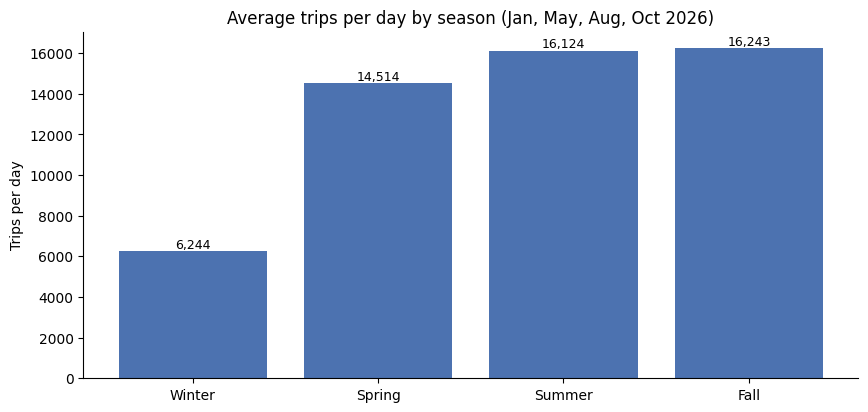

In [22]:
daily_s = c.assign(season=c["started_at"].dt.month.map(SEASON)).groupby(["season", "date"]).size()
by_season = daily_s.groupby("season").mean().reindex(["winter", "spring", "summer", "fall"])

fig, ax = plt.subplots()
ax.bar(by_season.index.str.title(), by_season.values, color="#4C72B0")
ax.set(title="Average trips per day by season (Jan, May, Aug, Oct 2026)", ylabel="Trips per day")
for i, v in enumerate(by_season.values):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.show()

## 8. Summary for the team
- The shared dataset is in `output/`, already split by day inside each month. **Do not shuffle** across splits.
- Every season appears in train, validation and test, so errors can be compared by `season` (Hypothesis 2).
- **Target:** `target_next_net_loss`. **Baseline:** `baseline_hist_avg` (Part 2 compares against it directly).
- Most station-hours have a target near 0; large values concentrate at a few stations during rush hours. That is why Part 4 should report a ranking metric (precision at top 10) in addition to MAE/RMSE.
- **For Part 3 (classification):** define "high loss" as the training set's 75th percentile of `target_next_net_loss`, and freeze that threshold before looking at val/test.
- **Parts 2 and 3 below** train the regression and classification models on the saved files. Re-run the save cell in section 6 first if you change the features.

In [23]:
train = model_df[model_df["split"] == "train"]
print("target distribution (train):")
print(train["target_next_net_loss"].describe().round(2))
for q in (0.75, 0.90):
    print(f"{q:.0%} percentile of the target (train):", train["target_next_net_loss"].quantile(q))
# Note for Part 3: if the 75th percentile is 0, "high loss" = target > 0 is very broad;
# the 90th percentile gives a more meaningful "station is losing bikes fast" label.

target distribution (train):
count    134400.00
mean         -0.00
std           2.63
min         -29.00
25%          -1.00
50%           0.00
75%           1.00
max          24.00
Name: target_next_net_loss, dtype: float64
75% percentile of the target (train): 1.0
90% percentile of the target (train): 3.0


## Part 2 — Regression

Predict each station's **next-hour net bike loss** (`target_next_net_loss`): departures minus arrivals in the following hour. Positive means the station is losing bikes. This is the hourly outcome the rest of the project forecasts.

Three predictors, fit on the training days only (days 8–21 of each month). Scores below are on the untouched test days (day 26 through the end of each month). Rows are never shuffled.

1. **Historical-average baseline** — training-set mean of the target for that station, weekday and hour (`baseline_hist_avg`).
2. **Linear regression**
3. **Random forest regression**

The two models see the baseline plus recent activity at the station, the same hour last week, calendar, weather and station location. A few columns are left out because they are exact copies of others: `arrivals` equals `departures − net_lag0`, `net_sum_3h` is the sum of the three most recent net-loss lags, `is_weekend` is determined by `day_of_week`, and `month` is determined by `season` (one month per season).

Requires `scikit-learn`. This section reads `output/station_hour_{train,val,test}.csv.gz` from Part 1.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error,
    precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay,
)

TARGET = "target_next_net_loss"
NUMERIC = [
    "baseline_hist_avg", "departures",
    "net_lag0", "net_lag1", "net_lag2", "net_lag3",
    "net_lag_1w", "dep_lag_1w",
    "casual_share", "ebike_share", "is_holiday",
    "lat", "lon", "capacity",
    "temp_c", "precip_mm", "wind_kmh", "is_raining",
]
CATEGORICAL = ["hour_of_day", "day_of_week", "season"]
FEATURES = NUMERIC + CATEGORICAL

def load_split(name):
    return pd.read_csv(f"output/station_hour_{name}.csv.gz", parse_dates=["hour", "target_hour"])

train = load_split("train")
val = load_split("val")
test = load_split("test")
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"rows — train {len(train):,} | val {len(val):,} | test {len(test):,}")

linear_prep = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])
tree_prep = ColumnTransformer([
    ("num", "passthrough", NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])

lin_reg = Pipeline([("prep", linear_prep), ("model", LinearRegression())])
rf_reg = Pipeline([
    ("prep", tree_prep),
    ("model", RandomForestRegressor(
        n_estimators=100, max_depth=14, min_samples_leaf=10,
        n_jobs=-1, random_state=42,
    )),
])
lin_reg.fit(X_train, y_train)
rf_reg.fit(X_train, y_train)

pred_test = {
    "Historical average": test["baseline_hist_avg"].to_numpy(),
    "Linear regression": lin_reg.predict(X_test),
    "Random forest": rf_reg.predict(X_test),
}
pred_train = {
    "Historical average": train["baseline_hist_avg"].to_numpy(),
    "Linear regression": lin_reg.predict(X_train),
    "Random forest": rf_reg.predict(X_train),
}
pred_val = {
    "Historical average": val["baseline_hist_avg"].to_numpy(),
    "Linear regression": lin_reg.predict(X_val),
    "Random forest": rf_reg.predict(X_val),
}

def regression_table(splits):
    rows = []
    for split, y, preds in splits:
        for name, pred in preds.items():
            rows.append({
                "model": name,
                "split": split,
                "MAE": mean_absolute_error(y, pred),
                "RMSE": root_mean_squared_error(y, pred),
            })
    table = pd.DataFrame(rows)
    wide = table.pivot(index="model", columns="split", values=["MAE", "RMSE"])
    wide = wide.reindex(["Historical average", "Linear regression", "Random forest"])
    wide = wide.reindex(columns=pd.MultiIndex.from_product([["MAE", "RMSE"], ["train", "val", "test"]]))
    return wide.round(3)

regression_scores = regression_table([
    ("train", y_train, pred_train),
    ("val", y_val, pred_val),
    ("test", y_test, pred_test),
])
regression_scores

rows — train 134,400 | val 38,400 | test 57,600


MAE                 RMSE              
                    train    val   test  train    val   test
model                                                       
Historical average  1.430  1.579  1.592  2.111  2.335  2.403
Linear regression   1.427  1.586  1.604  2.099  2.337  2.413
Random forest       1.290  1.546  1.525  1.881  2.318  2.342

The table above is in bikes per station-hour. **Test** is the comparison that matters: those days were not used to fit the models or the baseline. Train is shown because the baseline's training error is slightly optimistic (each station-hour contributes to its own average). Validation was not used for fitting.

On the test days the random forest is the only model that beats the historical average, and the gain is small. Most station-hours have a target near zero, and the station × weekday × hour average already captures the repeating commute pattern. Linear regression does not beat that average out of sample: a straight line cannot represent interactions such as a residential station emptying at 8am while a downtown station fills.

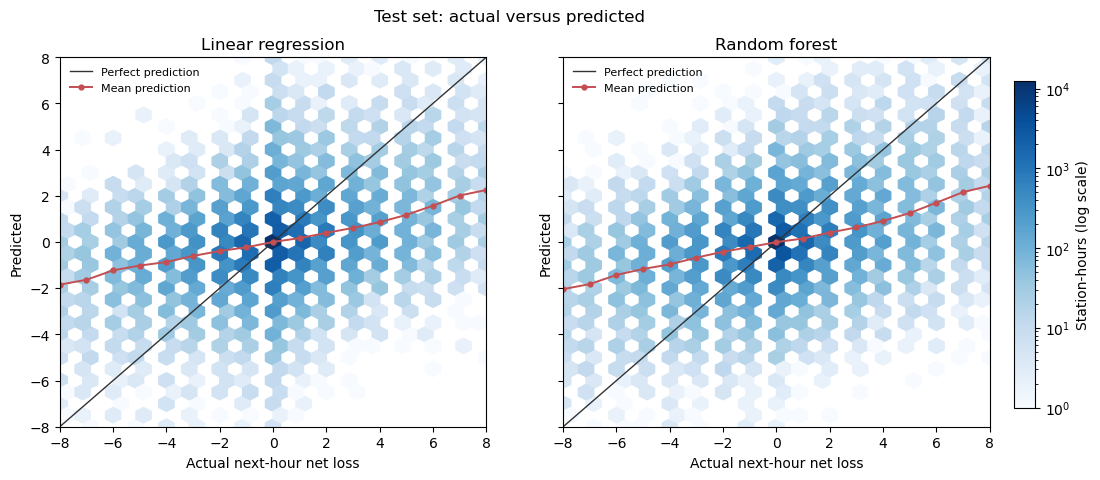

In [2]:
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
lo, hi = -8, 8
xs = np.arange(lo, hi + 1)
actual = y_test.to_numpy()
panels = []
for ax, name in zip(axes, ["Linear regression", "Random forest"]):
    pred = pred_test[name]
    panels.append(ax.hexbin(
        actual, pred, gridsize=28, cmap="Blues", mincnt=1,
        extent=(lo, hi, lo, hi), norm=LogNorm(),
    ))
    means = [pred[actual == k].mean() if np.any(actual == k) else np.nan for k in xs]
    ax.plot([lo, hi], [lo, hi], color="#333333", lw=1, label="Perfect prediction")
    ax.plot(xs, means, color="#c44e52", marker="o", ms=3.5, lw=1.4, label="Mean prediction")
    ax.set(title=name, xlabel="Actual next-hour net loss", ylabel="Predicted",
           xlim=(lo, hi), ylim=(lo, hi))
    ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.subplots_adjust(right=0.90, wspace=0.18, top=0.88)
cax = fig.add_axes([0.92, 0.15, 0.018, 0.68])
fig.colorbar(panels[1], cax=cax, label="Station-hours (log scale)")
fig.suptitle("Test set: actual versus predicted")
plt.show()


The black line is a perfect prediction. Colour is how many test station-hours fall in each bin, on a log scale, because most hours are near zero. The red line is the average prediction at each actual value. It rises with the truth but is much flatter than the diagonal: both models pull extreme hours back toward zero. That shrinkage is why a typical error stays near 1.5 bikes. The window is actual net loss from −8 to 8, which is where almost all hours sit.

## Part 3 — Classification

Predict whether the next hour is a **high-loss** hour.

The cutoff is the **75th percentile of `target_next_net_loss` on the training set only**. It is computed once and then frozen: validation and test use that same number, and it is not refit. An hour is high-loss when the target is **strictly above** the cutoff. On the training set that percentile is 1, so a high-loss hour is one where the station loses at least 2 bikes next hour. Many hours land exactly on 1, so this label covers about 19% of training hours rather than a full top quarter.

Both classifiers use the same features as the regression models. Class weights are balanced, because high-loss hours are the minority. That makes the models more willing to flag an hour, which raises recall and lowers precision. Precision, recall and F1 below are for the high-loss class.


In [3]:
threshold = float(y_train.quantile(0.75))
print(f"Frozen threshold (training 75th percentile of next-hour net loss): {threshold:.1f}")
print("High-loss = target > threshold")

y_train_cls = (y_train > threshold).astype(int)
y_val_cls = (y_val > threshold).astype(int)
y_test_cls = (y_test > threshold).astype(int)
for name, y in [("train", y_train_cls), ("val", y_val_cls), ("test", y_test_cls)]:
    print(f"share of high-loss hours ({name}): {y.mean():.1%}")

log_clf = Pipeline([
    ("prep", linear_prep),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
rf_clf = Pipeline([
    ("prep", tree_prep),
    ("model", RandomForestClassifier(
        n_estimators=100, max_depth=14, min_samples_leaf=10,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42,
    )),
])
log_clf.fit(X_train, y_train_cls)
rf_clf.fit(X_train, y_train_cls)

def classification_table(splits):
    rows = []
    for split, y, X in splits:
        for name, model in [("Logistic regression", log_clf), ("Random forest", rf_clf)]:
            pred = model.predict(X)
            rows.append({
                "model": name,
                "split": split,
                "precision": precision_score(y, pred, zero_division=0),
                "recall": recall_score(y, pred, zero_division=0),
                "F1": f1_score(y, pred, zero_division=0),
            })
    table = pd.DataFrame(rows)
    wide = table.pivot(index="model", columns="split", values=["precision", "recall", "F1"])
    wide = wide.reindex(["Logistic regression", "Random forest"])
    wide = wide.reindex(columns=pd.MultiIndex.from_product(
        [["precision", "recall", "F1"], ["val", "test"]]))
    return wide.round(3)

classification_scores = classification_table([
    ("val", y_val_cls, X_val),
    ("test", y_test_cls, X_test),
])
classification_scores

Frozen threshold (training 75th percentile of next-hour net loss): 1.0
High-loss = target > threshold
share of high-loss hours (train): 19.1%
share of high-loss hours (val): 17.5%
share of high-loss hours (test): 16.3%


precision        recall            F1       
                          val   test    val   test    val   test
model                                                           
Logistic regression     0.316  0.323  0.635  0.675  0.422  0.437
Random forest           0.338  0.349  0.565  0.623  0.423  0.448

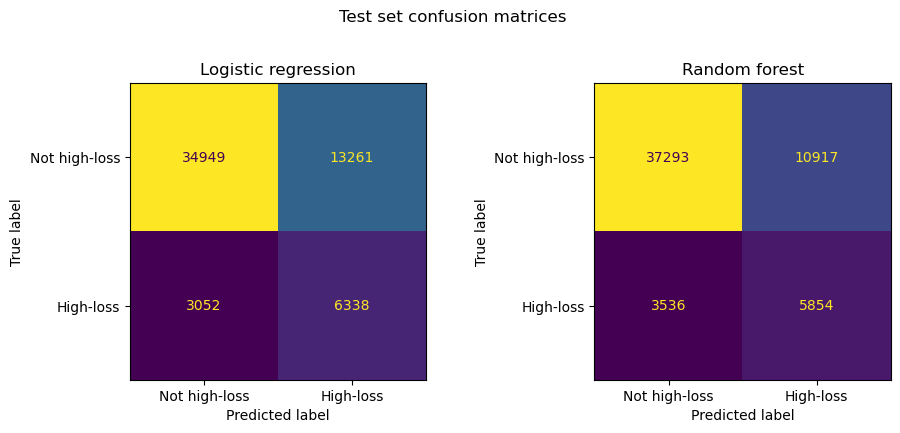

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, name, model in zip(
    axes,
    ["Logistic regression", "Random forest"],
    [log_clf, rf_clf],
):
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls, model.predict(X_test),
        display_labels=["Not high-loss", "High-loss"],
        ax=ax, colorbar=False,
    )
    ax.set_title(name)
fig.suptitle("Test set confusion matrices", y=1.02)
fig.tight_layout()
plt.show()

Read each matrix as counts of test station-hours. Rows are the true label, columns are the prediction.

Random forest has the higher test F1. Both models catch well over half of the true high-loss hours (recall) and are right about one time in three when they raise the flag (precision). That tradeoff comes from the balanced class weights: missing a station that is about to lose bikes is treated as worse than a false alarm. A probability cutoff other than 0.5 would move precision and recall in opposite directions; 0.5 is the default used here.

## Ranking the stations that need a crew

MAE treats a quiet overnight hour the same as a station that is about to empty. The decision each hour is which stations to visit. **Precision at 10** is the share of the 10 stations with the highest predicted net loss that are also among the 10 stations with the highest actual net loss. Ties are broken by `station_id`, so each hour has exactly 10 stations on each list. With 100 stations, a random list scores 0.10.

The score below uses the test days and the models already fit in Part 2.

In [5]:
def precision_at_k(frame, prediction, k=10):
    """Share of the predicted top k that are in the actual top k, averaged over hours."""
    df = frame[["target_hour", "station_id", TARGET]].copy()
    df["pred"] = np.asarray(prediction)
    df = df.sort_values(["target_hour", TARGET, "station_id"], ascending=[True, False, True])
    df["true_rank"] = df.groupby("target_hour", sort=False).cumcount() + 1
    df = df.sort_values(["target_hour", "pred", "station_id"], ascending=[True, False, True])
    df["pred_rank"] = df.groupby("target_hour", sort=False).cumcount() + 1
    flagged = df[df["pred_rank"] <= k]
    return (flagged["true_rank"] <= k).mean()

ranking_rows = []
for name, prediction in pred_test.items():
    ranking_rows.append({
        "model": name,
        "precision_at_10": precision_at_k(test, prediction),
    })
ranking_scores = pd.DataFrame(ranking_rows).set_index("model").round(3)
print(f"Hours scored: {test['target_hour'].nunique():,} | stations each hour: {test.groupby('target_hour').size().iloc[0]}")
print("A random top 10 scores 0.10.")
ranking_scores

Hours scored: 576 | stations each hour: 100
A random top 10 scores 0.10.


,precision_at_10
model,
Historical average,0.240
Linear regression,0.237
Random forest,0.239


On the test days every method gets about **2.4 of the 10** stations right. The historical average matches linear regression and the random forest. Extra features do not improve the crew list: the stations that lose the most bikes are mostly the ones that usually do, at that hour on that weekday.

## Rush hours only

Weekday mornings (7–9) and evenings (16–19) are where net loss actually moves. At 8am the training standard deviation is about 5 bikes, against under 1 bike in the middle of the night. The two models below are fit again on those training hours only, then scored on the same hours in the test days. The all-hours models are scored on those same test hours, so the comparison is the period a crew would care about.

In [6]:
RUSH_HOURS = [7, 8, 9, 16, 17, 18, 19]

def rush_mask(frame):
    return (frame["day_of_week"] < 5) & frame["hour_of_day"].isin(RUSH_HOURS)

train_rush = train.loc[rush_mask(train)]
test_rush = test.loc[rush_mask(test)]
print(f"Rush hours — train {len(train_rush):,} rows, test {len(test_rush):,} rows "
      f"({test_rush['target_hour'].nunique()} hours)")

def make_linear():
    prep = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([("prep", prep), ("model", LinearRegression())])

def make_forest():
    prep = ColumnTransformer([
        ("num", "passthrough", NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    model = RandomForestRegressor(
        n_estimators=100, max_depth=14, min_samples_leaf=10,
        n_jobs=-1, random_state=42,
    )
    return Pipeline([("prep", prep), ("model", model)])

lin_rush = make_linear()
rf_rush = make_forest()
lin_rush.fit(train_rush[FEATURES], train_rush[TARGET])
rf_rush.fit(train_rush[FEATURES], train_rush[TARGET])

rush_predictions = {
    "Historical average": test_rush["baseline_hist_avg"].to_numpy(),
    "Linear regression, all hours": lin_reg.predict(test_rush[FEATURES]),
    "Random forest, all hours": rf_reg.predict(test_rush[FEATURES]),
    "Linear regression, rush hours": lin_rush.predict(test_rush[FEATURES]),
    "Random forest, rush hours": rf_rush.predict(test_rush[FEATURES]),
}

rush_rows = []
for name, prediction in rush_predictions.items():
    rush_rows.append({
        "model": name,
        "MAE": mean_absolute_error(test_rush[TARGET], prediction),
        "RMSE": root_mean_squared_error(test_rush[TARGET], prediction),
        "precision_at_10": precision_at_k(test_rush, prediction),
    })
rush_scores = pd.DataFrame(rush_rows).set_index("model").round(3)
rush_scores

Rush hours — train 28,000 rows, test 12,600 rows (126 hours)


,MAE,RMSE,precision_at_10
model,,,
Historical average,2.473,3.302,0.319
"Linear regression, all hours",2.497,3.333,0.321
"Random forest, all hours",2.295,3.130,0.317
"Linear regression, rush hours",2.495,3.328,0.317
"Random forest, rush hours",2.308,3.135,0.321


Rush-hour errors are larger than the all-day MAE of about 1.5, because these hours are the ones with real bike movement. The random forest trained on every hour still has the lowest rush-hour MAE, about 2.30 against 2.47 for the historical average. Fitting it on rush hours only does not improve that, and precision at 10 stays near 0.32 for every method. Specializing the training rows does not fix the ranking.

## A tighter high-loss label

The 75th-percentile label (more than 1 bike) covers about 19% of training hours, so a flag is usually wrong. Here high-loss is frozen at the **training 90th percentile, which is 3 bikes**: the target is at least 3. Validation and test use that same cutoff.

The probability cutoff is chosen on the **validation** days, then frozen. The dispatch rule is a precision of at least **0.50** (a flag is right at least half the time). Among cutoffs that reach that precision, the one with the highest recall is kept, so the crew still hears about as many true high-loss hours as that precision allows. The test days are not used to pick the cutoff.

In [7]:
HIGH_LOSS_CUT = float(y_train.quantile(0.90))
DISPATCH_PRECISION = 0.50
print(f"Frozen high-loss cutoff (training 90th percentile): {HIGH_LOSS_CUT:.1f}")
print("High-loss = target >= cutoff")

y_train_hi = (y_train >= HIGH_LOSS_CUT).astype(int)
y_val_hi = (y_val >= HIGH_LOSS_CUT).astype(int)
y_test_hi = (y_test >= HIGH_LOSS_CUT).astype(int)
for split_name, labels in [("train", y_train_hi), ("val", y_val_hi), ("test", y_test_hi)]:
    print(f"share of high-loss hours ({split_name}): {labels.mean():.1%}")

def make_logistic():
    prep = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])

def make_forest_clf():
    prep = ColumnTransformer([
        ("num", "passthrough", NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    model = RandomForestClassifier(
        n_estimators=100, max_depth=14, min_samples_leaf=10,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42,
    )
    return Pipeline([("prep", prep), ("model", model)])

log_hi = make_logistic()
rf_hi = make_forest_clf()
log_hi.fit(X_train, y_train_hi)
rf_hi.fit(X_train, y_train_hi)

def dispatch_cutoff(model, X, y, min_precision=DISPATCH_PRECISION):
    """Lowest-miss cutoff whose validation precision is at least min_precision."""
    proba = model.predict_proba(X)[:, 1]
    best = None
    for cutoff in np.round(np.arange(0.05, 0.96, 0.01), 2):
        flagged = proba >= cutoff
        if flagged.sum() == 0:
            continue
        precision = precision_score(y, flagged, zero_division=0)
        recall = recall_score(y, flagged, zero_division=0)
        if precision + 1e-12 < min_precision:
            continue
        # Highest recall first; that is the most alarms still worth dispatching.
        key = (recall, precision, -cutoff)
        if best is None or key > best[0]:
            best = (key, cutoff, precision, recall)
    return None if best is None else best[1:]

chosen = {}
choice_rows = []
for name, model in [("Logistic regression", log_hi), ("Random forest", rf_hi)]:
    cutoff, val_precision, val_recall = dispatch_cutoff(model, X_val, y_val_hi)
    chosen[name] = cutoff
    test_flag = model.predict_proba(X_test)[:, 1] >= cutoff
    choice_rows.append({
        "model": name,
        "cutoff": cutoff,
        "val_precision": val_precision,
        "val_recall": val_recall,
        "test_precision": precision_score(y_test_hi, test_flag, zero_division=0),
        "test_recall": recall_score(y_test_hi, test_flag, zero_division=0),
        "test_F1": f1_score(y_test_hi, test_flag, zero_division=0),
        "test_flags": int(test_flag.sum()),
    })

dispatch_scores = pd.DataFrame(choice_rows).set_index("model")
dispatch_scores = dispatch_scores.round({
    "cutoff": 2, "val_precision": 3, "val_recall": 3,
    "test_precision": 3, "test_recall": 3, "test_F1": 3,
})
dispatch_scores

Frozen high-loss cutoff (training 90th percentile): 3.0
High-loss = target >= cutoff
share of high-loss hours (train): 11.5%
share of high-loss hours (val): 10.2%
share of high-loss hours (test): 10.0%


,cutoff,val_precision,val_recall,test_precision,test_recall,test_F1,test_flags
model,,,,,,,
Logistic regression,0.94,0.519,0.118,0.532,0.165,0.252,1788
Random forest,0.79,0.504,0.177,0.545,0.241,0.334,2544


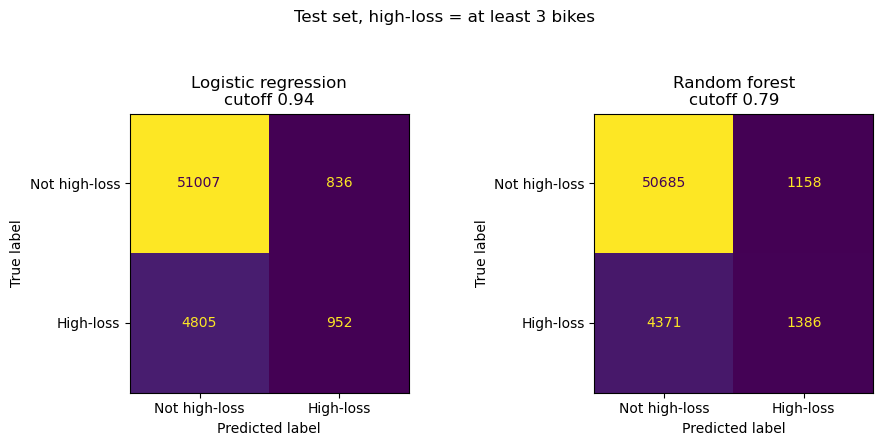

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, name, model in zip(axes, ["Logistic regression", "Random forest"], [log_hi, rf_hi]):
    flagged = model.predict_proba(X_test)[:, 1] >= chosen[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test_hi, flagged,
        display_labels=["Not high-loss", "High-loss"],
        ax=ax, colorbar=False,
    )
    ax.set_title(f"{name}\ncutoff {chosen[name]:.2f}")
fig.suptitle("Test set, high-loss = at least 3 bikes", y=1.05)
fig.tight_layout()
plt.show()

At a dispatch precision of 0.50, the random forest uses a probability cutoff of 0.79. On the test days its precision is 0.54 and its recall is 0.24: about half of the alarms are real, and about one in four true high-loss hours is caught. Logistic regression needs a cutoff of 0.94 to reach the same precision, and its recall falls to 0.17.

That is a usable alarm only if a missed station is acceptable. It is still a short list relative to flagging every hour above 1 bike, where precision was about 0.35.